In [20]:
# Install the libraries

!pip -q install pandas matplotlib seaborn transformers==4.46.3 sentencepiece sentence-transformers faiss-cpu

In [21]:
# Create the customer reviews dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "review_id": range(1, 16),
    "customer_review": [
        "The product quality is excellent and delivery was fast.",
        "Customer support was terrible and nobody answered my call.",
        "The product is okay, nothing special.",
        "I love this product. It works perfectly!",
        "Delivery was very late and the package was damaged.",
        "Good value for money. I would recommend it.",
        "The battery life is poor and disappointing.",
        "The product arrived on time and works as expected.",
        "I am very unhappy with the quality.",
        "Amazing experience! I will definitely buy again.",
        "The price is reasonable but delivery was slow.",
        "Customer service solved my problem quickly.",
        "It stopped working after two days. Very bad quality.",
        "The product is average and meets basic needs.",
        "Fantastic product and excellent customer service."
    ]
}

df = pd.DataFrame(data)

display(df.head())
print("Total reviews:", len(df))

,review_id,customer_review
0,1,The product quality is excellent and delivery ...
1,2,Customer support was terrible and nobody answe...
2,3,"The product is okay, nothing special."
3,4,I love this product. It works perfectly!
4,5,Delivery was very late and the package was dam...


Total reviews: 15


In [22]:
# Dataset Information

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nSample review:")
print(df["customer_review"].iloc[0])


Dataset shape: (15, 2)

Missing values:
review_id          0
customer_review    0
dtype: int64

Sample review:
The product quality is excellent and delivery was fast.


In [18]:
# Run sentiment analysis
# Sentiment analysis using a pretrained ML model

from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

results = sentiment_model(
    df["customer_review"].fillna("").tolist(),
    batch_size=8,
    truncation=True
)

df["sentiment"] = [r["label"] for r in results]
df["confidence"] = [round(r["score"], 4) for r in results]

display(df[["review_id", "customer_review", "sentiment", "confidence"]])

,review_id,customer_review,sentiment,confidence
0,1,The product quality is excellent and delivery ...,POSITIVE,0.9997
1,2,Customer support was terrible and nobody answe...,NEGATIVE,0.9997
2,3,"The product is okay, nothing special.",NEGATIVE,0.9859
3,4,I love this product. It works perfectly!,POSITIVE,0.9999
4,5,Delivery was very late and the package was dam...,NEGATIVE,0.9998
5,6,Good value for money. I would recommend it.,POSITIVE,0.9997
6,7,The battery life is poor and disappointing.,NEGATIVE,0.9997
7,8,The product arrived on time and works as expec...,POSITIVE,0.9953
8,9,I am very unhappy with the quality.,NEGATIVE,0.9997
9,10,Amazing experience! I will definitely buy again.,POSITIVE,0.9999


Sentiment counts:
sentiment
NEGATIVE    8
POSITIVE    7
Name: count, dtype: int64


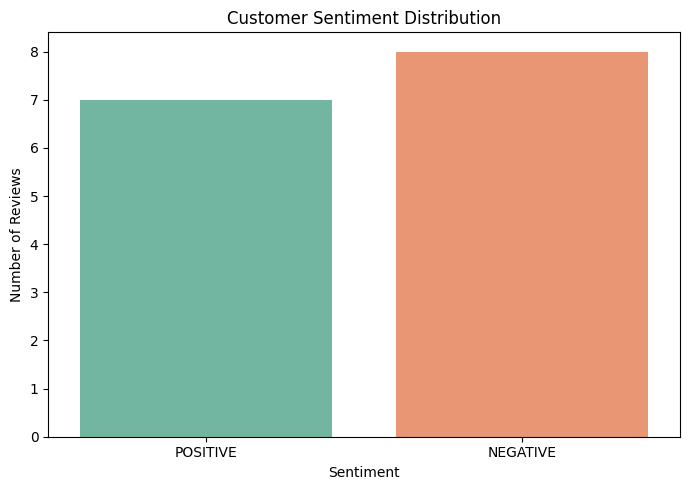

In [19]:
# Display sentiment distribution


print("Sentiment counts:")
print(df["sentiment"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=["POSITIVE", "NEGATIVE"],
    palette="Set2",
    legend=False
)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [23]:
# Create the FAISS search index again

# Build the customer feedback search engine By using RAG
# use Sentence Transformers + FAISS.


from sentence_transformers import SentenceTransformer
import faiss

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

reviews = df["customer_review"].fillna("").tolist()

embeddings = embedding_model.encode(
    reviews,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
).astype("float32")

index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)

print("FAISS index created!")
print("Reviews indexed:", index.ntotal)
print("Embedding dimensions:", embeddings.shape[1])


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

FAISS index created!
Reviews indexed: 15
Embedding dimensions: 384


In [24]:
# Create the review search function


def search_reviews(question, top_k=3):
    question_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    k = min(top_k, index.ntotal)
    scores, positions = index.search(question_embedding, k)

    results = df.iloc[positions[0]].copy()
    results["similarity"] = scores[0]

    return results[
        ["review_id", "customer_review", "sentiment", "similarity"]
    ].reset_index(drop=True)


In [1]:
# Install a compatible Transformers version

%pip install --no-cache-dir --force-reinstall "transformers==4.46.3" sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 85.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 211.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 220.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 197.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 177.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 272.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 272.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 172.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 249.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 317.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 283.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 294.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
import transformers

print("Transformers version:", transformers.__version__)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

Transformers version: 4.46.3


In [2]:
# Testing Model
# Make the AI generate answers
# add a lightweight language model so the system can answer questions using the reviews retrieved by FAISS. This makes it a basic Retrieval-Augmented Generation (RAG) pipeline.

from transformers import pipeline

generator = pipeline(
    "text2text-generation",
    model="google/flan-t5-small"
)

print("Model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Model loaded successfully!


In [28]:
# Create the customer insights function
# Building the RAG question-answering function


def ask_customer_voice(question, top_k=5):
    results = search_reviews(question, top_k=top_k)

    print("QUESTION:", question)
    print("\nRELEVANT CUSTOMER REVIEWS:")
    display(results)

    positive = int((results["sentiment"] == "POSITIVE").sum())
    negative = int((results["sentiment"] == "NEGATIVE").sum())
    total = len(results)

    print("\nCUSTOMER INSIGHTS:")
    print(f"Retrieved reviews: {total}")
    print(f"Positive reviews: {positive}")
    print(f"Negative reviews: {negative}")

    print("\nEVIDENCE FROM CUSTOMERS:")
    for _, row in results.iterrows():
        print(
            f"Review {row['review_id']} "
            f"({row['sentiment']}): {row['customer_review']}"
        )

    return results


In [32]:
# Testing Our Project
ask_customer_voice("What do customers say about delivery?")

QUESTION: What do customers say about delivery?

RELEVANT CUSTOMER REVIEWS:


,review_id,customer_review,sentiment,similarity
0,1,The product quality is excellent and delivery ...,POSITIVE,0.557523
1,11,The price is reasonable but delivery was slow.,NEGATIVE,0.499326
2,5,Delivery was very late and the package was dam...,NEGATIVE,0.474034
3,8,The product arrived on time and works as expec...,POSITIVE,0.417072
4,2,Customer support was terrible and nobody answe...,NEGATIVE,0.369633



CUSTOMER INSIGHTS:
Retrieved reviews: 5
Positive reviews: 2
Negative reviews: 3

EVIDENCE FROM CUSTOMERS:
Review 1 (POSITIVE): The product quality is excellent and delivery was fast.
Review 11 (NEGATIVE): The price is reasonable but delivery was slow.
Review 5 (NEGATIVE): Delivery was very late and the package was damaged.
Review 8 (POSITIVE): The product arrived on time and works as expected.
Review 2 (NEGATIVE): Customer support was terrible and nobody answered my call.


,review_id,customer_review,sentiment,similarity
0,1,The product quality is excellent and delivery ...,POSITIVE,0.557523
1,11,The price is reasonable but delivery was slow.,NEGATIVE,0.499326
2,5,Delivery was very late and the package was dam...,NEGATIVE,0.474034
3,8,The product arrived on time and works as expec...,POSITIVE,0.417072
4,2,Customer support was terrible and nobody answe...,NEGATIVE,0.369633


In [33]:
# IT Fixes the missing sentiment column


# 1. Check that the review dataset exists
print("Current columns:", df.columns.tolist())

# 2. Recreate sentiment model if needed
from transformers import pipeline

if "sentiment_model" not in globals():
    sentiment_model = pipeline(
        "sentiment-analysis",
        model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
    )

# 3. Generate sentiment labels again
results = sentiment_model(
    df["customer_review"].fillna("").tolist(),
    batch_size=8,
    truncation=True
)

df["sentiment"] = [r["label"] for r in results]
df["confidence"] = [round(r["score"], 4) for r in results]

# 4. Verify the result
display(df[["review_id", "customer_review", "sentiment", "confidence"]])

print("Sentiment column created successfully!")


Current columns: ['review_id', 'customer_review', 'sentiment', 'confidence']


,review_id,customer_review,sentiment,confidence
0,1,The product quality is excellent and delivery ...,POSITIVE,0.9997
1,2,Customer support was terrible and nobody answe...,NEGATIVE,0.9997
2,3,"The product is okay, nothing special.",NEGATIVE,0.9859
3,4,I love this product. It works perfectly!,POSITIVE,0.9999
4,5,Delivery was very late and the package was dam...,NEGATIVE,0.9998
5,6,Good value for money. I would recommend it.,POSITIVE,0.9997
6,7,The battery life is poor and disappointing.,NEGATIVE,0.9997
7,8,The product arrived on time and works as expec...,POSITIVE,0.9953
8,9,I am very unhappy with the quality.,NEGATIVE,0.9997
9,10,Amazing experience! I will definitely buy again.,POSITIVE,0.9999


Sentiment column created successfully!


In [34]:
ask_customer_voice("What do customers say about delivery?")

QUESTION: What do customers say about delivery?

RELEVANT CUSTOMER REVIEWS:


,review_id,customer_review,sentiment,similarity
0,1,The product quality is excellent and delivery ...,POSITIVE,0.557523
1,11,The price is reasonable but delivery was slow.,NEGATIVE,0.499326
2,5,Delivery was very late and the package was dam...,NEGATIVE,0.474034
3,8,The product arrived on time and works as expec...,POSITIVE,0.417072
4,2,Customer support was terrible and nobody answe...,NEGATIVE,0.369633



CUSTOMER INSIGHTS:
Retrieved reviews: 5
Positive reviews: 2
Negative reviews: 3

EVIDENCE FROM CUSTOMERS:
Review 1 (POSITIVE): The product quality is excellent and delivery was fast.
Review 11 (NEGATIVE): The price is reasonable but delivery was slow.
Review 5 (NEGATIVE): Delivery was very late and the package was damaged.
Review 8 (POSITIVE): The product arrived on time and works as expected.
Review 2 (NEGATIVE): Customer support was terrible and nobody answered my call.


,review_id,customer_review,sentiment,similarity
0,1,The product quality is excellent and delivery ...,POSITIVE,0.557523
1,11,The price is reasonable but delivery was slow.,NEGATIVE,0.499326
2,5,Delivery was very late and the package was dam...,NEGATIVE,0.474034
3,8,The product arrived on time and works as expec...,POSITIVE,0.417072
4,2,Customer support was terrible and nobody answe...,NEGATIVE,0.369633


In [35]:
# Create a Customer Insights Dashboard
# Sentiment summary


# Summary of customer sentiment
sentiment_summary = (
    df.groupby("sentiment")
    .agg(
        total_reviews=("review_id", "count"),
        average_confidence=("confidence", "mean")
    )
    .reset_index()
)

sentiment_summary["average_confidence"] = (
    sentiment_summary["average_confidence"] * 100
).round(2)

print("Customer Sentiment Summary")
display(sentiment_summary)


Customer Sentiment Summary


,sentiment,total_reviews,average_confidence
0,NEGATIVE,8,99.47
1,POSITIVE,7,99.83


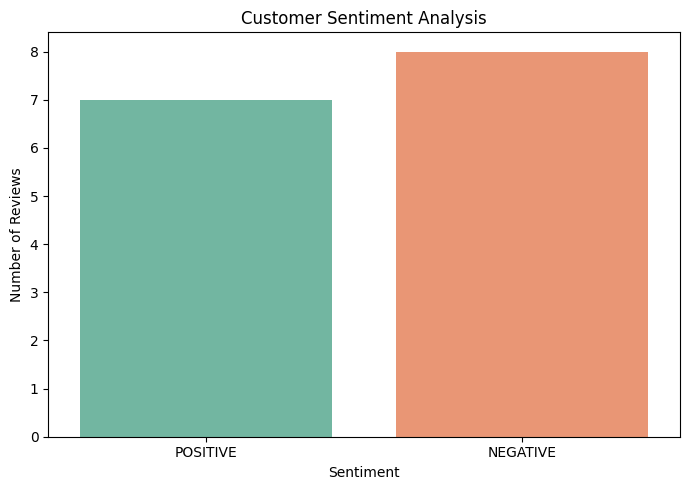

In [36]:
# Visualize customer sentiment


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    palette="Set2",
    legend=False
)

plt.title("Customer Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


,word,frequency
0,product,6
1,quality,3
2,delivery,3
3,customer,3
4,excellent,2
5,works,2
6,service,2
7,fast,1
8,support,1
9,terrible,1


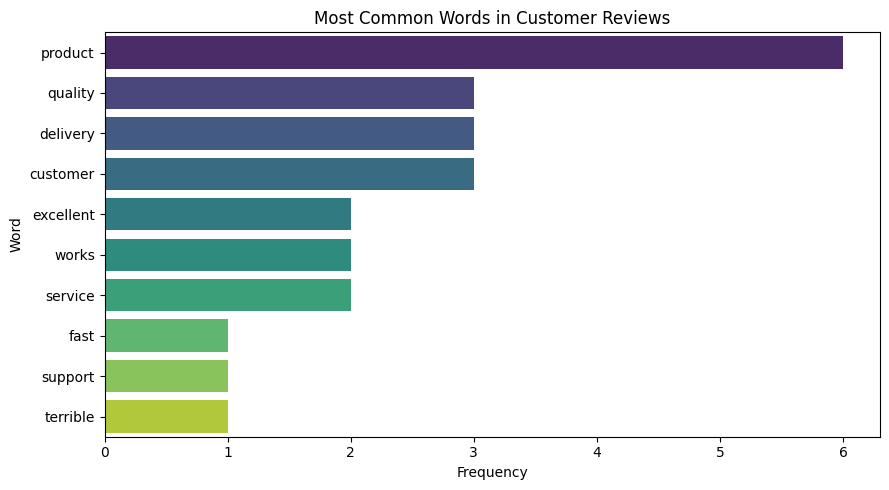

In [37]:
# Find common customer complaint words


from collections import Counter
import re

stop_words = {
    "the", "and", "was", "is", "it", "a", "to", "my",
    "i", "very", "with", "but", "after", "for", "on",
    "this", "of", "as", "an", "be", "would", "will"
}

all_text = " ".join(
    df["customer_review"].fillna("").str.lower()
)

words = re.findall(r"\b[a-z]+\b", all_text)

word_counts = Counter(
    word for word in words
    if word not in stop_words and len(word) > 2
)

common_words = pd.DataFrame(
    word_counts.most_common(10),
    columns=["word", "frequency"]
)

display(common_words)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=common_words,
    x="frequency",
    y="word",
    hue="word",
    palette="viridis",
    legend=False
)
plt.title("Most Common Words in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


In [38]:
# Save your analyzed data


output_file = "customer_voice_ai_results.csv"

df.to_csv(output_file, index=False)

print("Export completed:", output_file)


Export completed: customer_voice_ai_results.csv


In [39]:
# Create a professional project summary

# built the main parts of Customer Voice AI — Sentiment & Insights: sentiment analysis, semantic review search, evidence-based insights, charts, and CSV export.


readme_content = """
# Customer Voice AI — Sentiment & Insights

## Overview
Customer Voice AI is a beginner-friendly data analytics and AI project
that analyzes customer reviews, classifies sentiment, retrieves relevant
feedback using semantic search, and visualizes customer insights.

## Objectives
- Classify customer reviews as positive or negative.
- Search reviews based on the meaning of a question.
- Retrieve relevant customer feedback using vector similarity.
- Visualize sentiment distribution and common review words.
- Export analyzed data to CSV for further analysis.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Hugging Face Transformers
- Sentence Transformers
- FAISS
- Google Colab

## Project Workflow
1. Load customer review data.
2. Apply pretrained sentiment analysis.
3. Generate sentence embeddings.
4. Index reviews using FAISS.
5. Retrieve relevant reviews for a question.
6. Analyze sentiment patterns and visualize results.
7. Export results to CSV.

## Dataset
This prototype uses 15 sample customer reviews.
The results are intended for demonstration and are not representative
of actual customer populations.

## Limitations
- The sample dataset is small.
- Sentiment classification uses positive and negative labels only.
- Retrieved reviews and similarity scores should be reviewed before
  making business decisions.
- The current version provides evidence-based summaries rather than
  reliable free-form AI-generated answers.

## Future Improvements
- Use a larger real-world customer review dataset.
- Add a neutral sentiment category.
- Build an interactive dashboard.
- Evaluate model performance on labeled data.
- Add a more reliable retrieval-augmented generation model.

## Author
Aspiring Data Analyst | Python | SQL | Excel | Data Visualization
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!
